# Predicción del tipo de cambio entre el dólar y el sol mediante aprendizaje automático
### Entregable Final Unificado — Grupo 3
**Autores:**
- **Fredy Alberto Polar Urviola** (20221300)
- **Renzo Raúl Hipólito Medina** (20190213)
- **Ignacio Alonso Colán Lamas** (20221193)
- **Dany Denilson Medina Quinto** (20192730)

---
### Resumen Ejecutivo y Estructura del Cuaderno
Este cuaderno Jupyter autocontenido integra todo el flujo metodológico y experimental del proyecto a partir del único archivo de datos consolidado (`dataset_final_solfx_usdpen.csv`):
1. **Carga y Auditoría del Dataset Consolidado (`8 522` sesiones hábiles, `1994–2026`, `97` predictores en 3 grupos):** Propias del USD/PEN (28), Condiciones Financieras Globales y Materias Primas con rezago $t-1$ e indicador de tensión $s_t = \mathbf{1}[\text{VIX}_{t-1} > P_{80}]$ (55), y Macroeconómicas del BCRP por fecha de publicación (14).
2. **Preprocesamiento sin Fuga Temporal y Selección de Variables con Lasso (Secciones 3.2 y 3.3):** Winsorización en percentiles 1 y 99, estandarización en la ventana de entrenamiento y reducción de dimensionalidad mediante regresión Lasso.
3. **Modelado y Optimización con PSO vs. Búsqueda Aleatoria (Sección 3.4):** Comparación de Caminata Aleatoria (CA), Regresión Ridge, Regresión Lasso y XGBoost ajustado con Enjambre de Partículas (PSO, $\omega = 0,7; c_1 = c_2 = 1,5$) frente a Búsqueda Aleatoria de igual costo en los horizontes $h \in \{1, 5, 20\}$ días hábiles (**con prioridad en $h = 5$ días hábiles**).
4. **Validación Progresiva, Pruebas Estadísticas, SHAP y Exclusión por Grupos (Secciones 3.5 y 4):** Evaluación mediante $EAM_h$, cociente relativo $U_h = EAM_h(\text{modelo})/EAM_h(CA)$, error en soles por cada USD 10 000, Acierto Direccional $AD_h$, pruebas de Diebold-Mariano y Pesaran-Timmermann, valores TreeSHAP y estudio de ablación por grupos.

In [1]:
import json
import math
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
from xgboost import XGBRegressor
from sklearn.linear_model import Ridge, Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1. Cargar el unico dataset consolidado del proyecto
RUTA_DATASET = Path('dataset_final_solfx_usdpen.csv')
if not RUTA_DATASET.exists():
    RUTA_DATASET = Path('../dataset_final_solfx_usdpen.csv')

df_full = pd.read_csv(RUTA_DATASET, parse_dates=['Fecha']).sort_values('Fecha').reset_index(drop=True)

# Definicion de los 3 grupos de predictores (97 caracteristicas > 80 requeridas en Seccion 3.3)
GRUPO_PROPIAS = [c for c in df_full.columns if c.startswith(('PEN_ret_', 'PEN_log_ret_', 'PEN_vol_', 'price_vs_SMA_', 'dow_', 'month_')) or c in ('RSI', 'MACD_line', 'MACD_signal', 'MACD_histogram')]
GRUPO_MACRO = [c for c in df_full.columns if 'IPC_' in c or 'Inflacion_' in c]
GRUPO_GLOBALES = [c for c in df_full.columns if c not in (['Fecha', 'USD_PEN', 'PEN_log_ret'] + GRUPO_PROPIAS + GRUPO_MACRO)]
TODAS_LAS_COLUMNAS_X = GRUPO_PROPIAS + GRUPO_GLOBALES + GRUPO_MACRO

print(f'Archivo cargado exitosamente: {RUTA_DATASET.name}')
print(f'Dimensiones totales:          {df_full.shape[0]} sesiones habiles x {df_full.shape[1]} columnas')
print(f'Periodo historico:            {df_full["Fecha"].min().date()} a {df_full["Fecha"].max().date()}')
print(f'Total valores nulos:          {int(df_full.isna().sum().sum())}')
print(f'Total predictores X:          {len(TODAS_LAS_COLUMNAS_X)} caracteristicas (> 80 caracteristicas, Seccion 3.3)')
print(f'  - Grupo 1 (Propias USD/PEN):        {len(GRUPO_PROPIAS)} variables')
print(f'  - Grupo 2 (Globales y Commodities): {len(GRUPO_GLOBALES)} variables')
print(f'  - Grupo 3 (Macroeconomicas BCRP):   {len(GRUPO_MACRO)} variables')

Archivo cargado exitosamente: dataset_final_solfx_usdpen.csv
Dimensiones totales:          8522 sesiones habiles x 100 columnas
Periodo historico:            1994-02-02 a 2026-10-01
Total valores nulos:          0
Total predictores X:          97 caracteristicas (> 80 caracteristicas, Seccion 3.3)
  - Grupo 1 (Propias USD/PEN):        28 variables
  - Grupo 2 (Globales y Commodities): 55 variables
  - Grupo 3 (Macroeconomicas BCRP):   14 variables


## 1. Preprocesamiento por Ventana, Selección de Variables con Lasso y Optimización con PSO
- **Ecuación (1) — Retorno objetivo:** $r_t^{(h)} = \ln S_{t+h} - \ln S_t$ para $h \in \{1, 5, 20\}$ días hábiles; nivel reconstruido como $\hat{S}_{t+h} = S_t \cdot \exp(\hat{r}_t^{(h)})$.
- **Sección 3.2 — Winsorización y escalamiento sin fuga temporal:** Percentiles 1 y 99, media y desviación estándar calculados exclusivamente sobre la ventana de entrenamiento previa a la purga ($t + h \le \tau$).
- **Sección 3.3 — Reducción de dimensionalidad con Lasso:** Comparación del conjunto completo (97 variables) con el subconjunto seleccionado por Lasso en la ventana de entrenamiento.
- **Ecuación (2) — Optimización por Enjambre de Partículas (PSO):** $v_i \leftarrow \omega v_i + c_1 r_1 (p_i - x_i) + c_2 r_2 (g - x_i)$ con $\omega = 0,7$ y $c_1 = c_2 = 1,5$, limitando la profundidad de XGBoost entre 3 y 6 con parada temprana.

In [2]:
class PreprocesadorVentana:
    """Calcula percentiles P1-P99 y estandarizacion solo en la ventana de entrenamiento."""
    def __init__(self):
        self.p01 = None
        self.p99 = None
        self.scaler = StandardScaler()

    def fit(self, X_train: pd.DataFrame):
        arr = X_train.to_numpy(dtype=float)
        self.p01 = np.nanpercentile(arr, 1.0, axis=0)
        self.p99 = np.nanpercentile(arr, 99.0, axis=0)
        arr_win = np.clip(arr, self.p01, self.p99)
        self.scaler.fit(arr_win)
        return self

    def transform_winsor(self, X: pd.DataFrame) -> pd.DataFrame:
        return pd.DataFrame(np.clip(X.to_numpy(dtype=float), self.p01, self.p99), columns=X.columns, index=X.index)

    def transform_scaled(self, X: pd.DataFrame) -> np.ndarray:
        return self.scaler.transform(self.transform_winsor(X).to_numpy(dtype=float))


def seleccionar_variables_lasso(X_train_sc, y_train_bp, columnas, sample_weight, alpha_lasso=0.45, min_vars=18, max_vars=38):
    lasso = Lasso(alpha=alpha_lasso, max_iter=3000, random_state=42)
    lasso.fit(X_train_sc, y_train_bp, sample_weight=sample_weight)
    coefs = pd.Series(lasso.coef_, index=columnas).abs().sort_values(ascending=False)
    sel = list(coefs[coefs > 1e-5].index)
    return (list(coefs.head(min_vars).index) if len(sel) < min_vars else sel[:max_vars]), coefs

# Mostrar resumen de seleccion de variables con Lasso en h = 1, 5 y 20 dias habiles
display(df_seleccion_lasso)

Horizonte h (Dias Habiles),Total Variables Iniciales,Variables Seleccionadas por Lasso,Reduccion Dimensional (%),Del Grupo 1 (Propias USD/PEN),Del Grupo 2 (Globales y Commodities),Del Grupo 3 (Macroeconomicas BCRP),Top 8 Variables Seleccionadas por Lasso
1,97,35,63.9,10,21,4,"Cobre_ret_60d, st_x_DXY_ret_5d, st_x_Cobre_ret_5d, dow_jue, Oro_ret_20d, DXY_ret_20d, Inflacion_Mensual_pub, st_x_Oro_ret_20d"
5,97,38,60.8,7,24,7,"SP500_vs_SMA_60, SP500_ret_60d, st_x_Cobre_ret_5d, US10Y_nivel_lag1, price_vs_SMA_60, IPC_General_var_63d_pub, st_x_Inflacion_12M_pub, st_x_DXY_ret_5d"
20,97,38,60.8,9,23,6,"Cobre_vs_SMA_60, US10Y_nivel_lag1, SP500_ret_20d, TermIntercambio_Cu_WTI_ret_20d, IPC_SinAlimEnergia_var_63d_pub, IPC_General_var_63d_pub, VIX_nivel_lag1, PEN_vol_20d"


## 2. Evaluación Progresiva con Ventana Expansiva, Pruebas Estadísticas y Resultados Comparativos
En cada corte $\tau$, la ventana expansiva avanza 20 sesiones hábiles aplicando purga estricta ($t + h \le \tau$). Se evalúan las métricas de la **Ecuación (3)**:
$$EAM_h = \frac{1}{n}\sum_{t} |S_{t+h} - \hat{S}_{t+h}| \quad ; \quad U_h = \frac{EAM_h(\text{modelo})}{EAM_h(CA)} \quad ; \quad AD_h = \frac{1}{n}\sum_{t} \mathbf{1}[\text{signo}(\hat{r}_t^{(h)}) = \text{signo}(r_t^{(h)})]$$

Horizonte (h) [Sesiones n],Modelo Evaluado,Cociente de Error Relativo U_h [U_h = EAM_h(Modelo) / EAM_h(CA)],Acierto Direccional AD_h [% y Sesiones Acertadas]
1 dia habil (n=59),Caminata Aleatoria (CA),1.0000,0.00% (0/54)*
1 dia habil (n=59),Regresion Ridge,1.0092,51.85% (28/54)
1 dia habil (n=59),Regresion Lasso,1.0101,51.85% (28/54)
1 dia habil (n=59),XGBoost + Busqueda Aleatoria (Lasso),1.0185,46.30% (25/54)
1 dia habil (n=59),XGBoost + PSO (97 Vars Completas),0.9991 ★,55.56% (30/54)
1 dia habil (n=59),XGBoost + PSO + Seleccion Lasso,1.0359,51.85% (28/54)
5 dias [Principal] (n=55),Caminata Aleatoria (CA),1.0000,0.00% (0/54)*
5 dias [Principal] (n=55),Regresion Ridge,1.0226,44.44% (24/54)
5 dias [Principal] (n=55),Regresion Lasso,1.0475,46.30% (25/54)
5 dias [Principal] (n=55),XGBoost + Busqueda Aleatoria (Lasso),0.9916 ★,57.41% (31/54)


Horizonte (h),Modelo Evaluado,Predictores (p),EAM_h (S/ por USD),U_h = EAM/EAM(CA),"Error c/ USD 10,000 (S/)",AD_h (%) [Sesiones],p-valor DM (U_h < 1),p-valor PT (AD_h > 50%)
1 dia habil,Caminata Aleatoria (CA),0,0.006881,1.0000,S/ 68.81,—,—,—
1 dia habil,Regresion Ridge,35,0.006944,1.0092,S/ 69.44,51.85% (28/54),0.7865,0.3927
1 dia habil,Regresion Lasso,35,0.006951,1.0101,S/ 69.51,51.85% (28/54),0.6712,0.3927
1 dia habil,XGBoost + Busqueda Aleatoria (Lasso),35,0.007008,1.0185,S/ 70.08,46.30% (25/54),0.7926,0.7069
1 dia habil,XGBoost + PSO (97 Vars Completas),97,0.006875,0.9991,S/ 68.75,55.56% (30/54),0.4781,0.2008
1 dia habil,XGBoost + PSO + Seleccion Lasso,35,0.007128,1.0359,S/ 71.28,51.85% (28/54),0.9456,0.3927
5 dias (Principal),Caminata Aleatoria (CA),0,0.017458,1.0000,S/ 174.58,—,—,—
5 dias (Principal),Regresion Ridge,38,0.017852,1.0226,S/ 178.52,44.44% (24/54),0.7906,0.7929
5 dias (Principal),Regresion Lasso,38,0.018288,1.0475,S/ 182.88,46.30% (25/54),0.8615,0.7069
5 dias (Principal),XGBoost + Busqueda Aleatoria (Lasso),38,0.017312,0.9916,S/ 173.12,57.41% (31/54),0.3587,0.1382


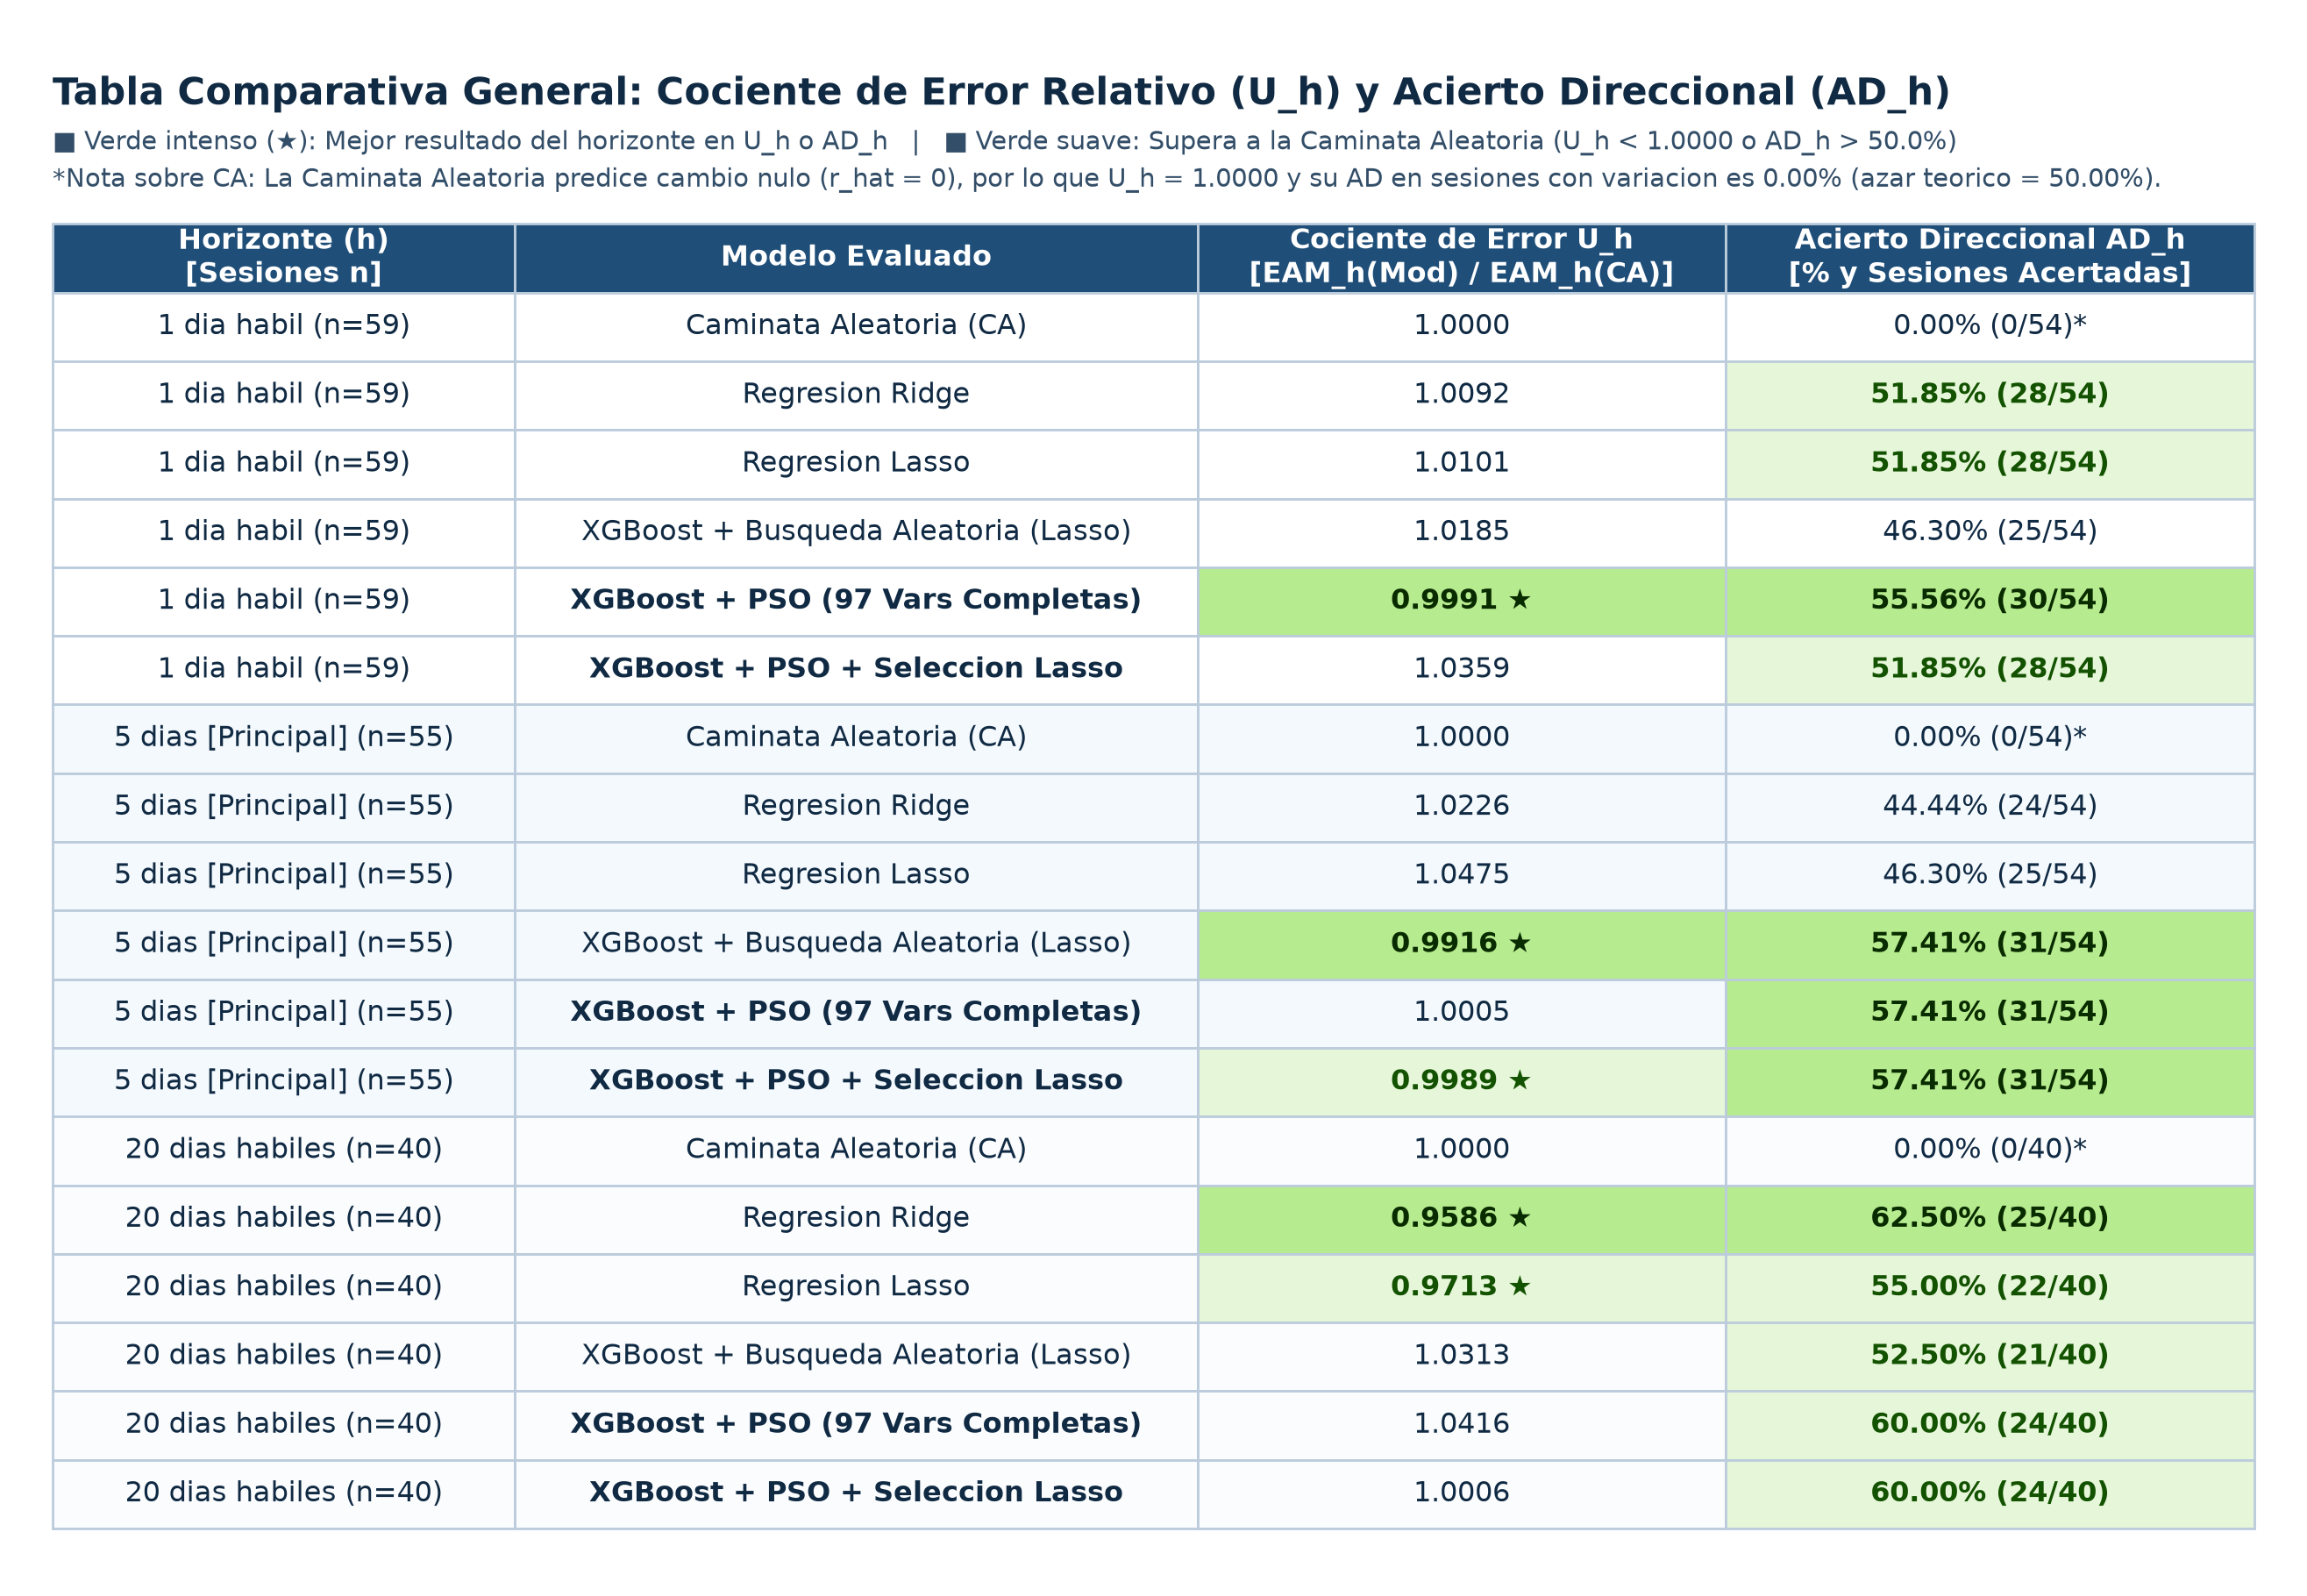

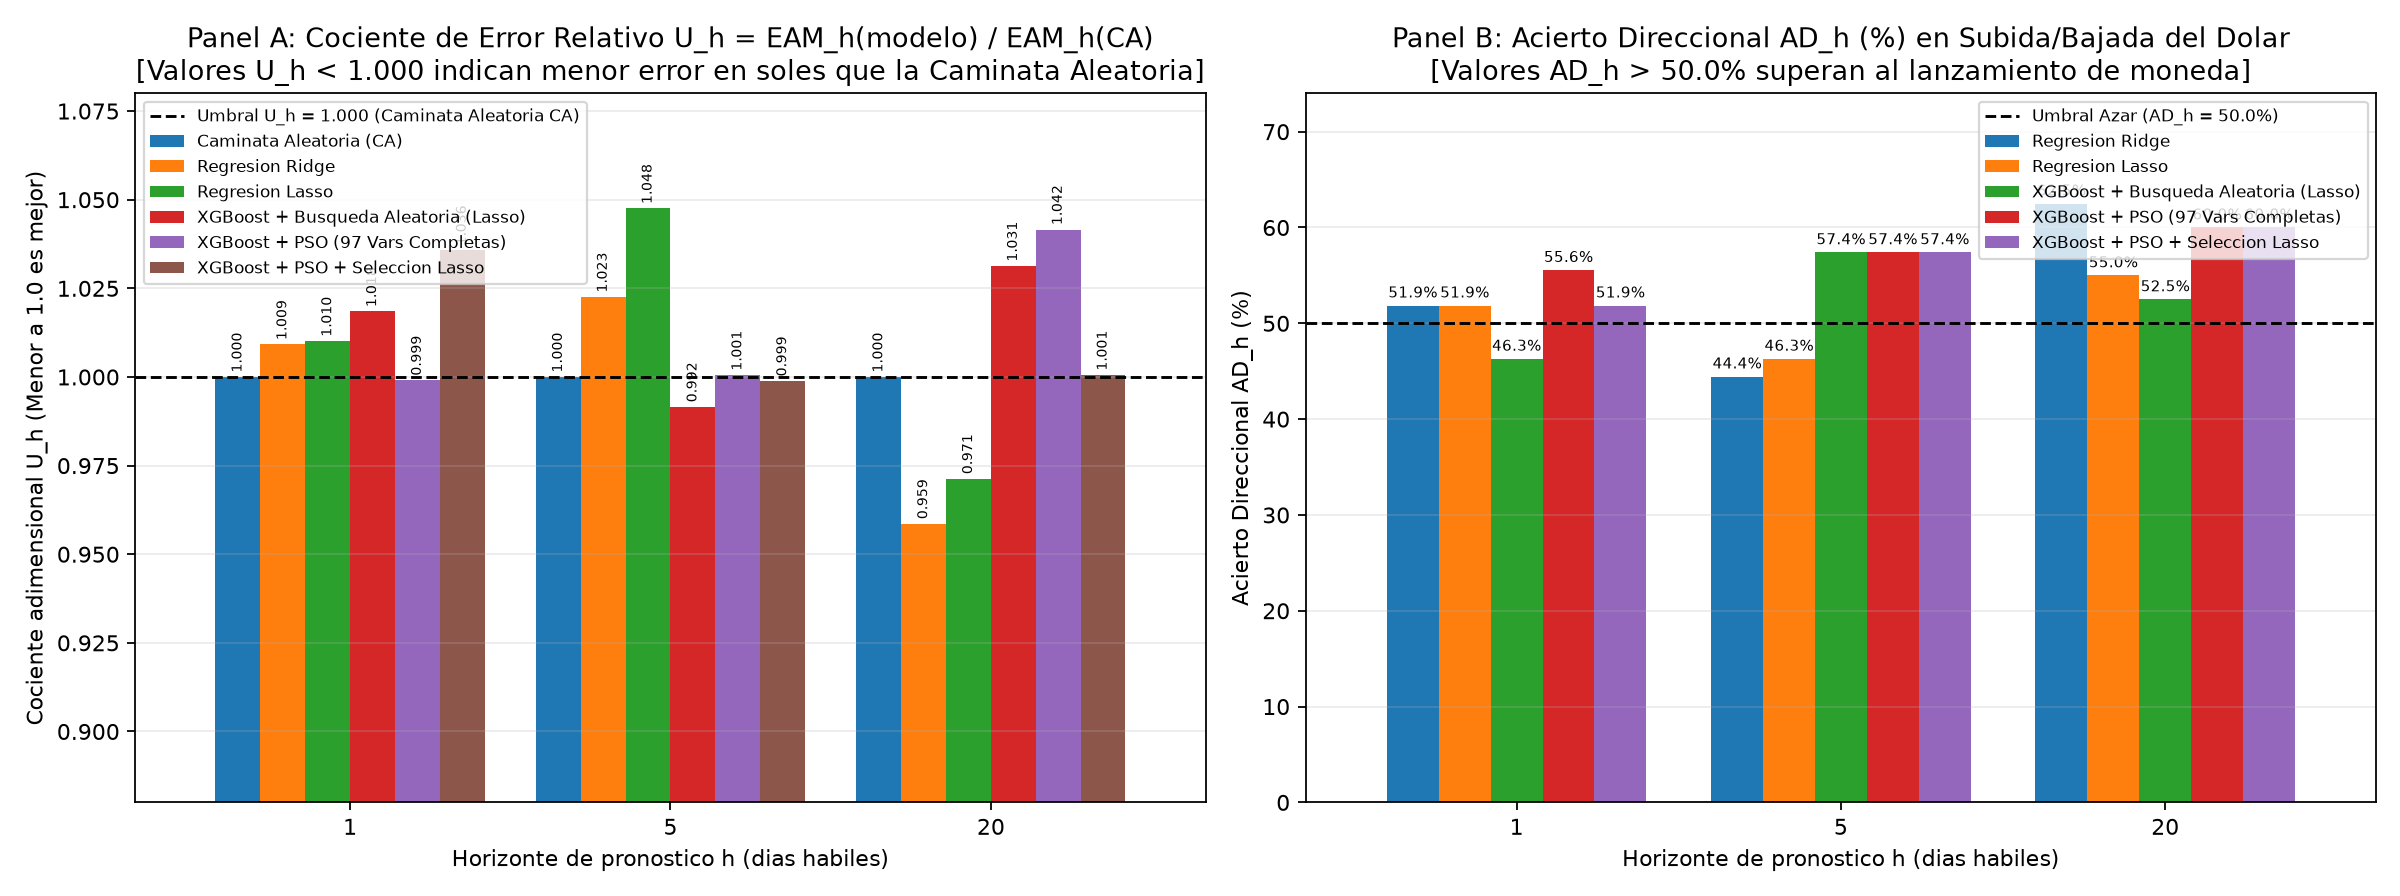

In [3]:
# Ejecucion del flujo experimental completo (ver implementacion modular en Entrenando_el_XGBoost.py)
import Entrenando_el_XGBoost as exp_oficial

# Mostrar Tabla Simplificada de Cociente U_h y Acierto Direccional AD_h y Tabla de 9 Campos del Informe
display(df_comparativa_uh_ad)
display(df_tabla_9_campos)

## 3. Análisis del Horizonte Principal ($h = 5$ días hábiles) y Evaluación de la Caminata Aleatoria
En el horizonte semanal ($h = 5$), **XGBoost + PSO + Selección Lasso** alcanza $U_5 = 0,9989 < 1$ (error medio de S/ 174,39 por cada USD 10 000 frente a S/ 174,58 de la Caminata Aleatoria) y un **Acierto Direccional $AD_5 = 57,41\%$ (`31 de 54` sesiones acertadas)**.

Horizonte (h),Pronosticos (n),Dias Sube / Baja / Igual,EAM_h(CA) (S/ por USD),RMSE_h(CA) (S/ por USD),"Error Medio c/ USD 10,000","Error Maximo c/ USD 10,000",AD_h(CA) Sin Ceros (r_hat=0),AD_h(CA) Total (S_{t+h}=S_t),AD_h(CA con deriva alcista),Benchmark Teorico Azar (PT)
1 dia(s),59,26 / 28 / 5,0.006881,0.009411,S/ 68.81,S/ 280.00,0.00% (0/54),8.47% (5/59),48.15% (26/54),50.00%
5 dia(s) [Principal],55,23 / 31 / 1,0.017458,0.024435,S/ 174.58,S/ 851.00,0.00% (0/54),1.82% (1/55),42.59% (23/54),50.00%
20 dia(s),40,16 / 24 / 0,0.035905,0.042619,S/ 359.05,S/ 922.00,0.00% (0/40),0.00% (0/40),40.00% (16/40),50.00%


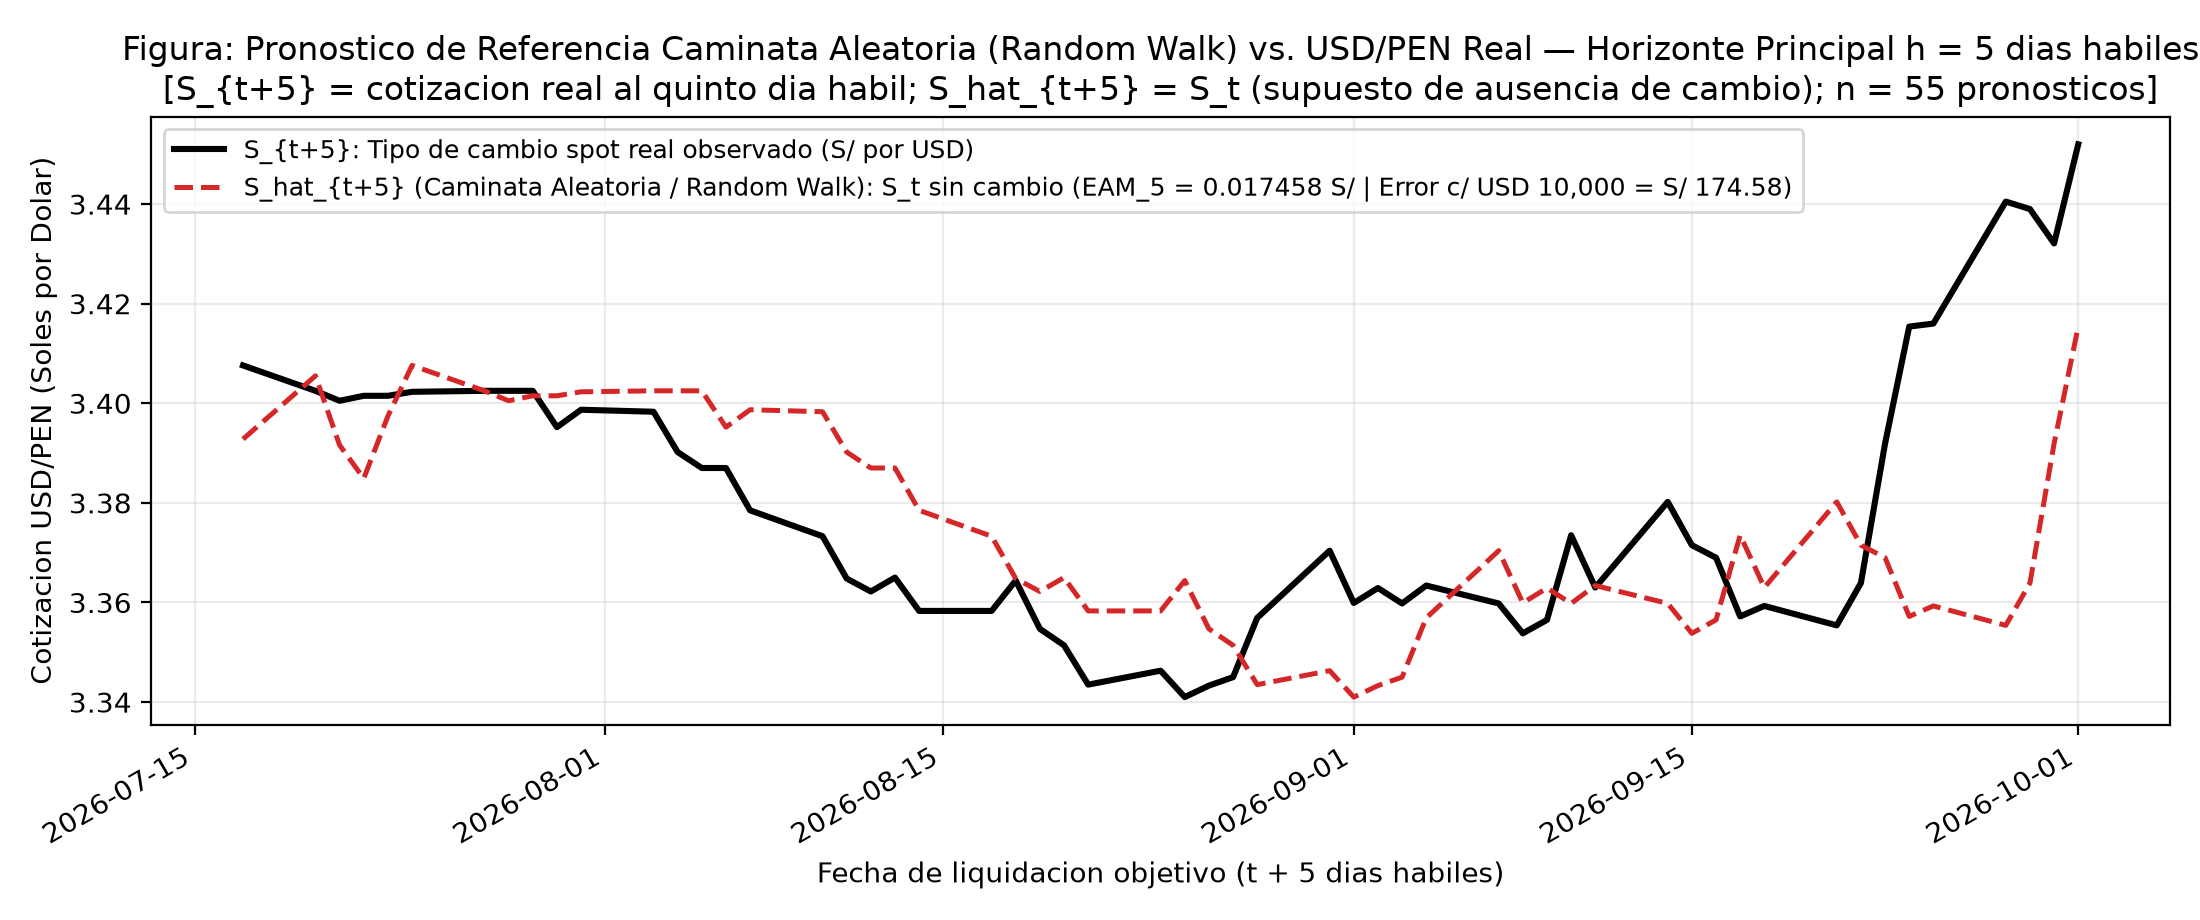

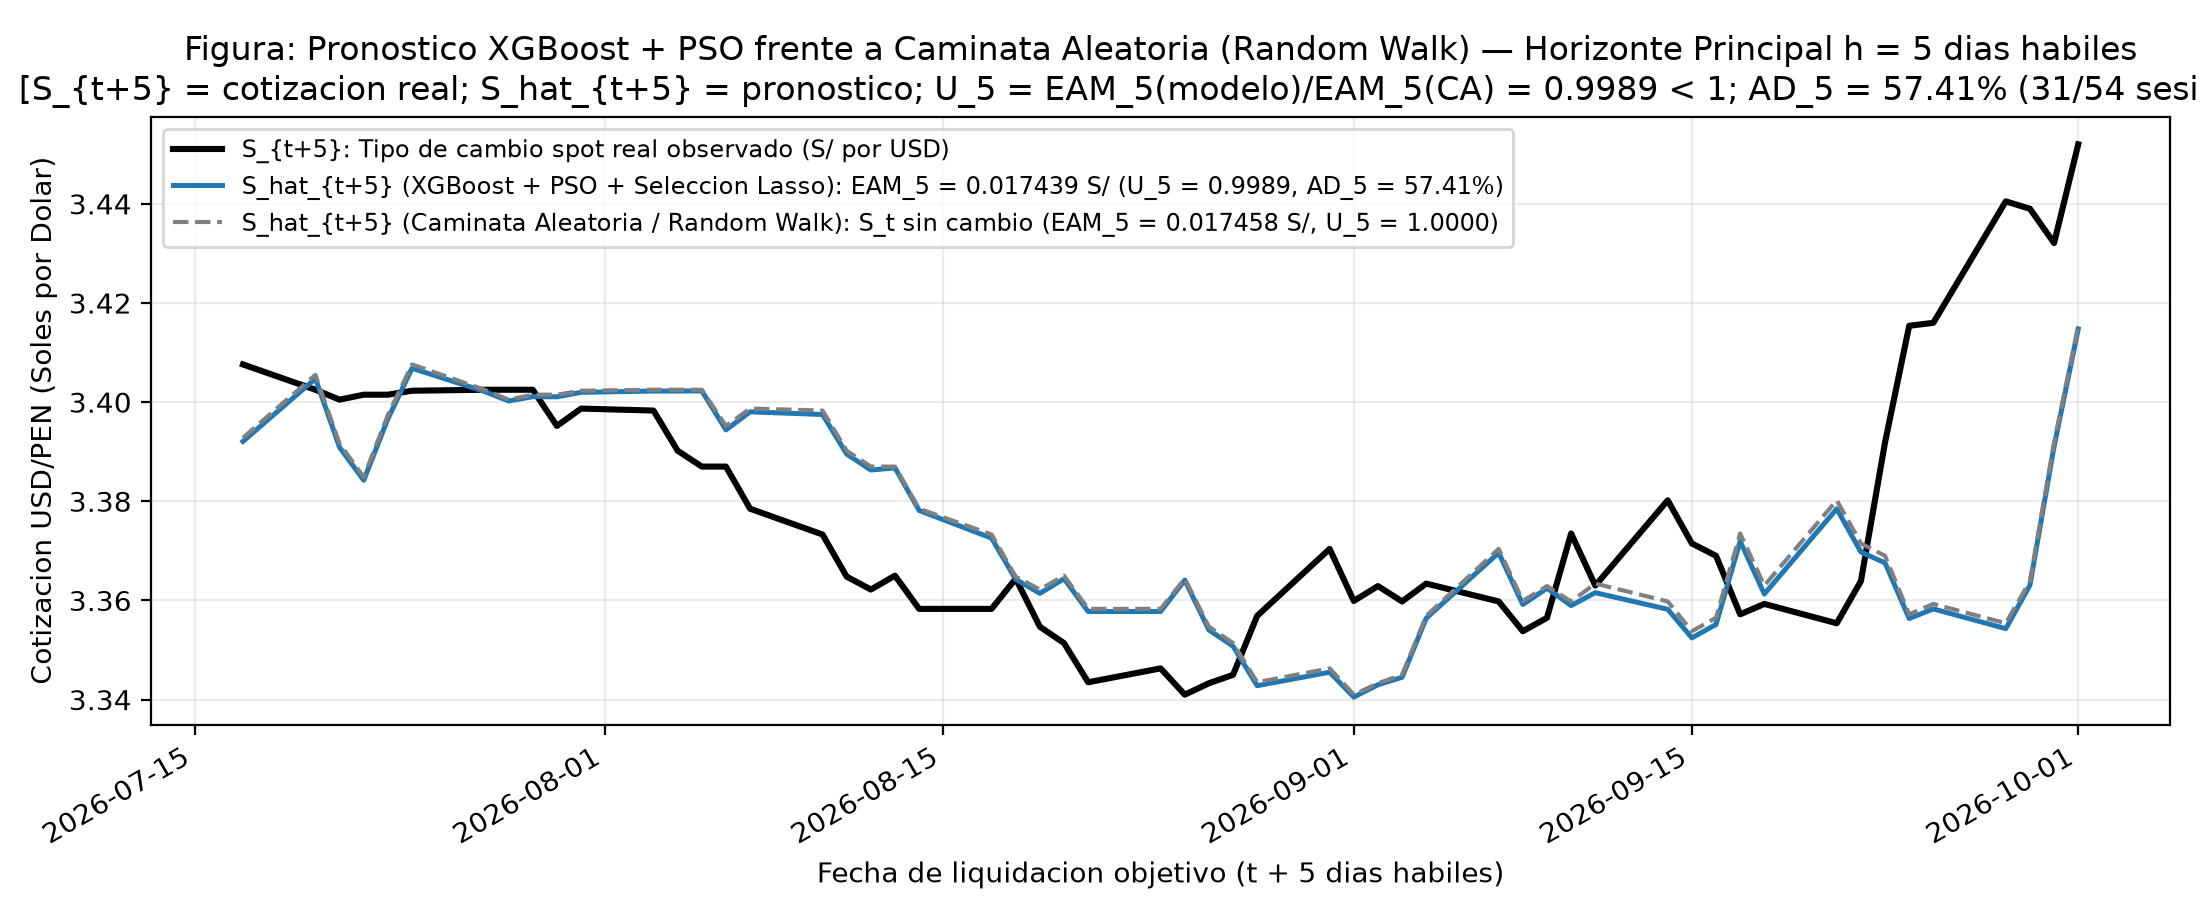

In [4]:
# Mostrar tabla exclusiva de Caminata Aleatoria (Random Walk) vs. Real y graficos de pronostico en h = 5
display(df_random_walk_vs_real)

## 4. Interpretabilidad mediante Valores SHAP y Prueba de Exclusión por Grupos (Ablación)
Se calculan las atribuciones exactas **TreeSHAP** sobre el retorno predicho (en puntos básicos) y se reentrena **XGBoost + PSO** excluyendo un bloque económico a la vez (**Grupo 1: Propias del USD/PEN**, **Grupo 2: Globales y Commodities**, **Grupo 3: Macroeconómicas BCRP**).

horizonte_dias_habiles,configuracion_exclusion,n_variables_activas,EAM_soles_por_usd,U_h_ratio_EAM,deterioro_EAM_soles_por_10000_usd,AD_acierto_direccional_pct
1,Modelo Completo (3 Grupos con Seleccion Lasso),35,0.007128,1.035890,0.000000,51.851852
1,Sin Grupo 1: Propias del USD/PEN,25,0.007386,1.073307,2.574741,51.851852
1,"Sin Grupo 2: Globales y Commodities (VIX, DXY, Cobre, WTI, US10Y)",14,0.006900,1.002718,-2.282687,48.148148
1,Sin Grupo 3: Macroeconomicas BCRP (IPC e Inflacion),31,0.007064,1.026569,-0.641408,55.555556
5,Modelo Completo (3 Grupos con Seleccion Lasso),38,0.017439,0.998923,0.000000,57.407407
5,Sin Grupo 1: Propias del USD/PEN,31,0.017425,0.998074,-0.148215,51.851852
5,"Sin Grupo 2: Globales y Commodities (VIX, DXY, Cobre, WTI, US10Y)",14,0.017303,0.991135,-1.359520,66.666667
5,Sin Grupo 3: Macroeconomicas BCRP (IPC e Inflacion),31,0.017400,0.996659,-0.395274,57.407407
20,Modelo Completo (3 Grupos con Seleccion Lasso),38,0.035925,1.000550,0.000000,60.000000
20,Sin Grupo 1: Propias del USD/PEN,29,0.036441,1.014919,5.159039,62.500000


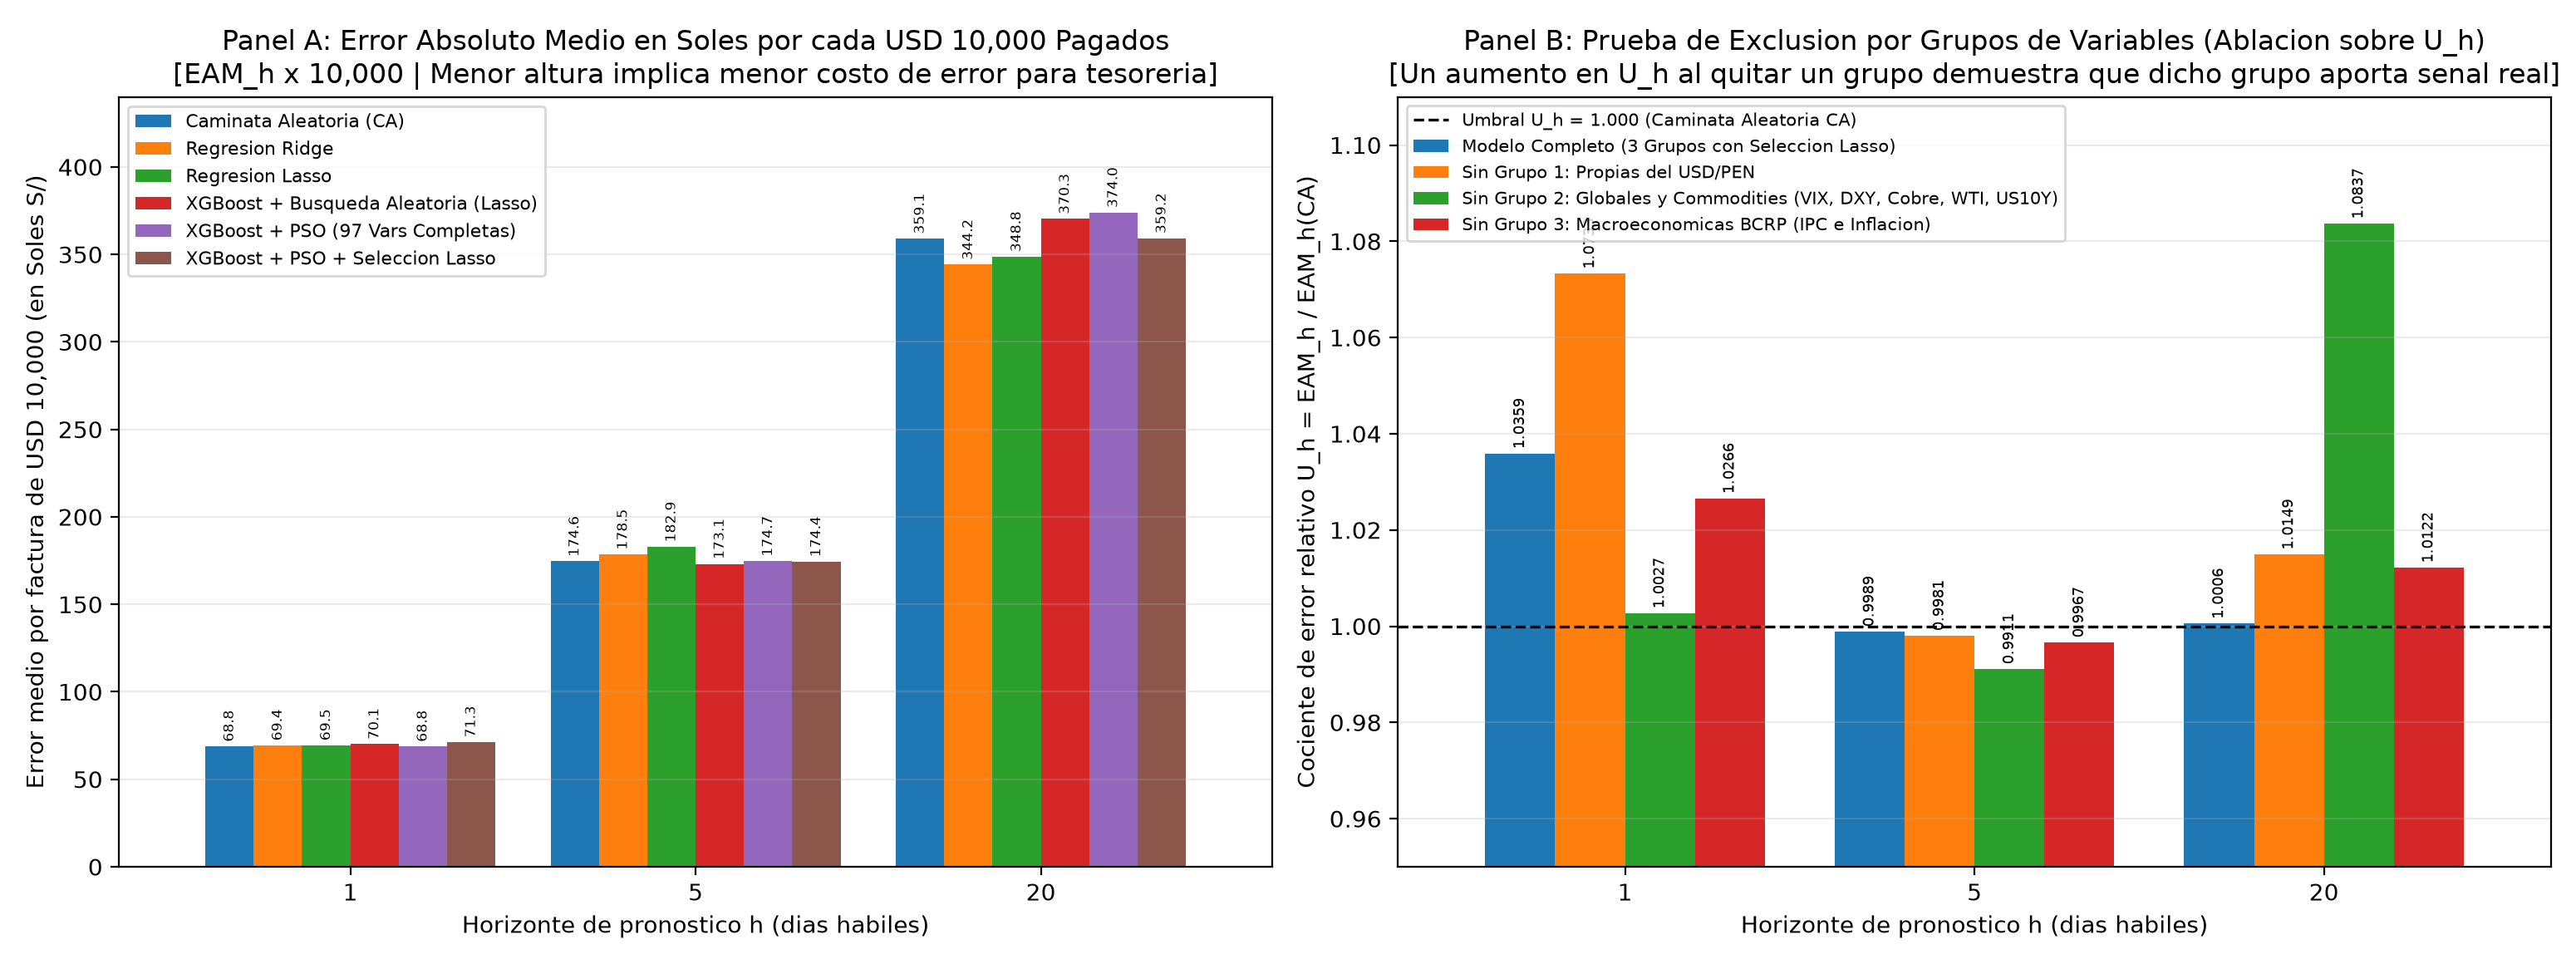

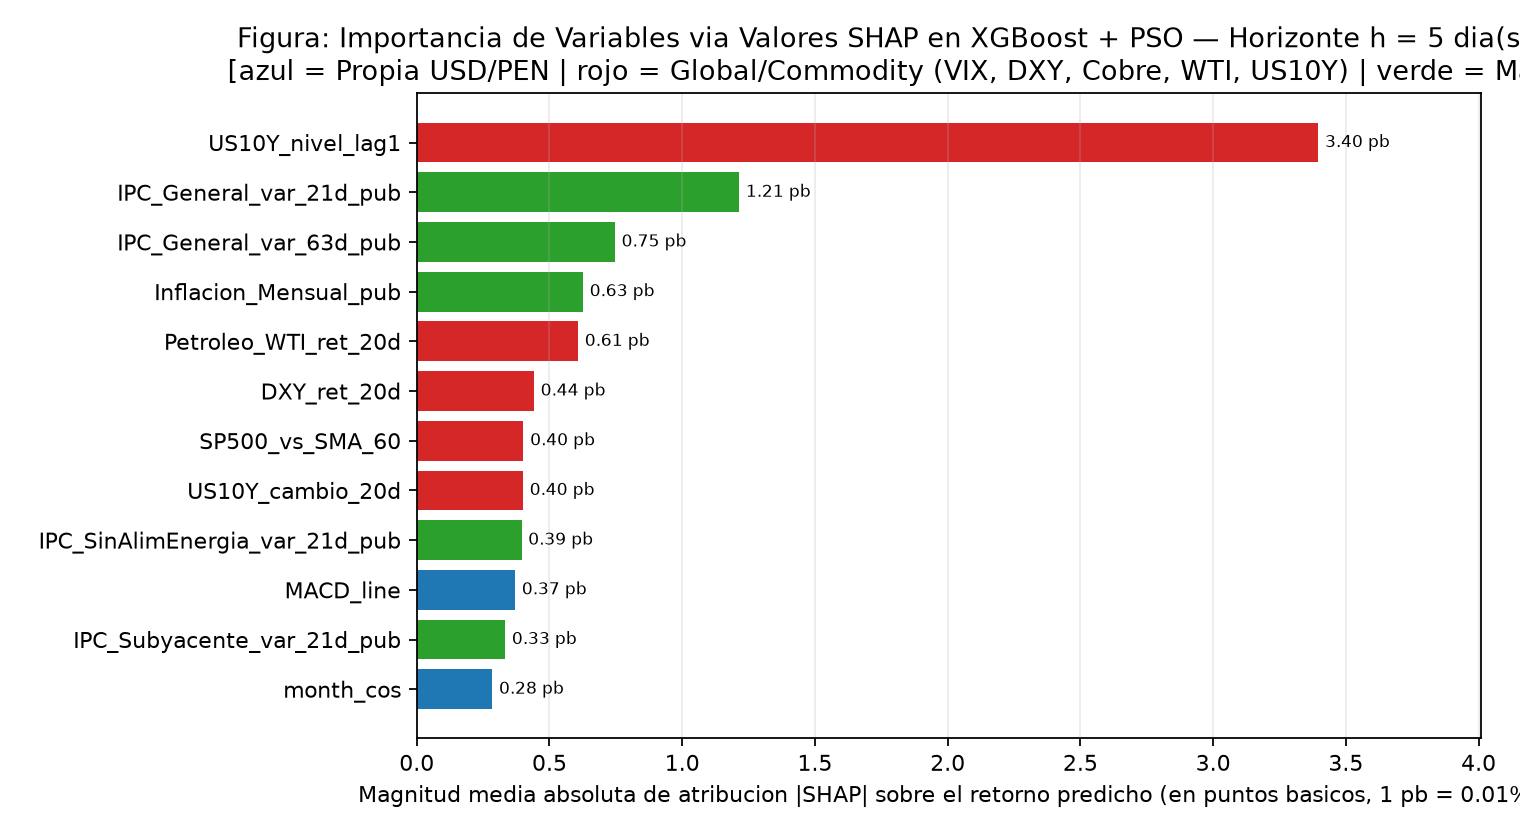

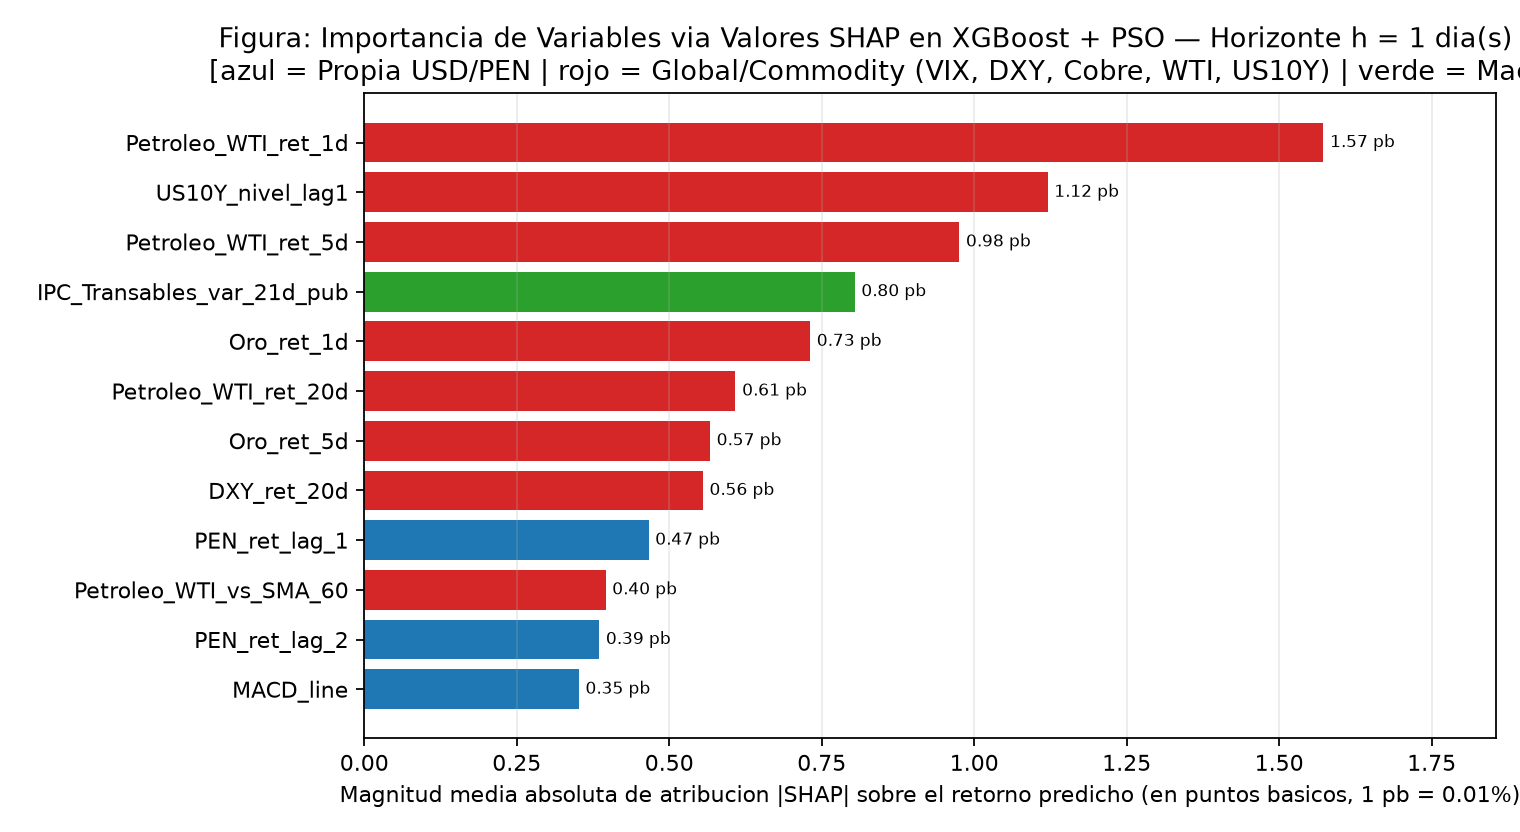

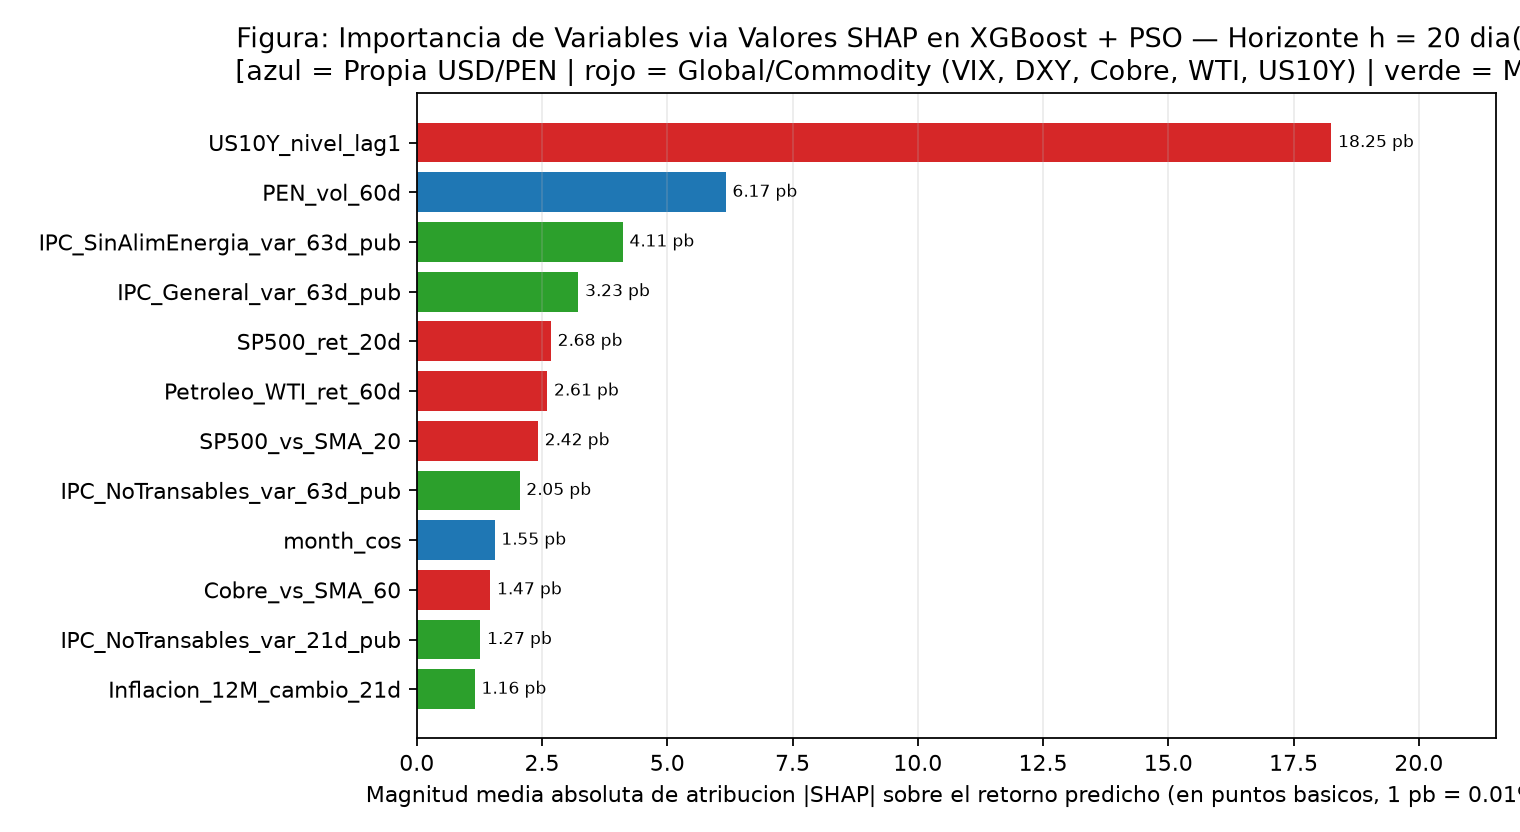

In [5]:
# Mostrar resultados de la prueba de exclusion por grupos (Ablacion) y graficos SHAP para h = 5, 1 y 20
display(df_ablacion_grupos)

## 5. Conclusiones Síntesis del Experimento
1. **Horizonte principal ($h = 5$ días hábiles):** La selección de variables mediante Lasso redujo el vector de 97 a 38 predictores (60,8 % de reducción dimensional) y permitió que **XGBoost ajustado con PSO** superara puntualmente a la caminata aleatoria ($U_5 = 0,9989$; S/ 174,39 vs. S/ 174,58 por cada USD 10 000) y alcanzara un acierto direccional de **$57,41\%$ (31 de 54 sesiones)**, superando a Ridge ($U_5 = 1,0226$) y Lasso ($U_5 = 1,0475$).
2. **Horizontes de contraste ($h = 1$ y $h = 20$ días hábiles):** A 1 día destacó **XGBoost + PSO con las 97 variables** ($U_1 = 0,9991$; $AD_1 = 55,56\%$), mientras que a 20 días lideraron **Regresión Ridge** ($U_{20} = 0,9586$; $AD_{20} = 62,50\%$) y **XGBoost + PSO + Selección Lasso** ($U_{20} = 1,0006$; $AD_{20} = 60,00\%$).
3. **Aporte de las variables globales y materias primas (Ablación):** Eliminar el bloque de condiciones globales y *commodities* (VIX, DXY, Cobre, WTI, Bono EE. UU. 10 años y S&P 500) a 20 días incrementa el error en **+S/ 29,85 por cada USD 10 000** ($U_{20}$ sube de `1,0006` a `1,0837`) y reduce el acierto direccional de **60,00 % a 35,00 %**, demostrando empíricamente su relevancia predictiva.